# Privacy Group Stance over Time

| Item | Description |
|---|---|
| Goal | Plot annual net stance with Wilson intervals for the full Privacy and digital consumer protection group, not Topic 68 alone. |
| Input | The approved `topic_groups.csv`; saved `track2_assigned.parquet` and `hearings_sst.parquet` under `/project2/mmiric_1435/acroh/llm_method/data`. |
| Output | One single-panel net-stance figure in PNG, SVG, and PDF, plus annual and administration-level count CSVs in `output/T2.4.2/` beside this notebook. |
| Unit | An original extracted stance record: a legislator's position on a topic. A speech turn may contain multiple records. This retains the reference figure's measure, unlike the distinct-turn bars in T2.4.1. |
| Sample | All records assigned to the approved privacy group's topics in House Science and Senate Commerce hearings held in 1999–2025. |
| Group definition | Topic groups manually cluster topics from topic extraction. The mapping file determines membership; no individual topic identifier is hard-coded. |
| Stances | Support means endorsement, advocacy, or urging adoption, funding, or expansion of a topic. Concern means worry, criticism, objection, or urging restriction, delay, or scrutiny. Definitions follow the Track 2 extraction prompt reproduced in Appendix A.2 of `Proposal_for_Org_Sci_101126_AR.md`. |
| Sources | • Wilson, E. B. (1927). *Probable inference, the law of succession, and statistical inference*. Journal of the American Statistical Association, 22(158), 209–212. [doi:10.1080/01621459.1927.10502953](https://doi.org/10.1080/01621459.1927.10502953). Binomial score interval for the support share, transformed to the net-stance scale.<br>• [SciPy: BinomTestResult.proportion_ci](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats._result_classes.BinomTestResult.proportion_ci.html), `method="wilson"` without continuity correction. |
| Variables | • `support_records` and `concern_records`: $S_t$ and $C_t$, numbers of support and concern records in hearing year $t$.<br>• `n_records`: $N_t=S_t+C_t$, total stance records.<br>• `n_hearings`, `n_turns`, and `n_legislators`: distinct hearings, speech turns, and legislators represented in each period.<br>• `support_share`: $p_t=S_t/N_t$, fraction of records expressing support.<br>• `net_stance`: $(S_t-C_t)/N_t=2p_t-1$, ranging from −1 (all concern) to +1 (all support).<br>• `net_ci_lower` and `net_ci_upper`: 95 percent Wilson support-share bounds transformed as $2p-1$. |
| Administration means | Pool all records in each calendar-year block: Clinton 1999–2000, Bush 2001–2008, Obama 2009–2016, Trump I 2017–2020, Biden 2021–2024, and Trump II 2025. These are sample windows, not exact inauguration dates. |
| Interpretation | Intervals are descriptive, treating records as independent; they do not account for repeated records within turns, legislators, or hearings. No break-year search, minimum-cell threshold, or screening test is applied. |

Follow the shared figure guide: one panel per image, a fixed 9-by-6-inch canvas, the prescribed colors and serif font, and captions outside the exported image. This notebook is independent of the raw-turn export notebook.

## Step 1. Import packages

Read saved data, calculate Wilson intervals with SciPy, and display the exported figures.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.stats import binomtest
from IPython.display import Image, Markdown, display

## Step 2. Define file locations

Read the source files in place and save outputs in `output/T2.4.2/` beside this notebook.

In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SOURCE_DATA_FOLDER = Path("/project2/mmiric_1435/acroh/llm_method/data")
NOTEBOOK_SUBFOLDER = Path(
    "T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection"
)
GROUPS_FILE = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "topic_groups.csv"
RECORDS_FILE = SOURCE_DATA_FOLDER / "interim/topics/taxonomy/track2_assigned.parquet"
HEARINGS_FILE = SOURCE_DATA_FOLDER / "interim/repo_data/raw/02_hearings/hearings_sst.parquet"
OUTPUT_FOLDER = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output" / "T2.4.2"

TARGET_GROUP = "Privacy and digital consumer protection"
YEAR_MIN = 1999
YEAR_MAX = 2025
CONFIDENCE_LEVEL = 0.95
TURN_KEYS = ["packageId", "turn_idx"]
ADMINISTRATION_WINDOWS = [
    ("Clinton", 1999, 2000),
    ("Bush", 2001, 2008),
    ("Obama", 2009, 2016),
    ("Trump I", 2017, 2020),
    ("Biden", 2021, 2024),
    ("Trump II", 2025, 2025),
]
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")

Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.2


## Step 3. Apply the figure style

Use the shared canvas, font, colors, and margins, with the requested slightly thicker zero line. Use DejaVu Serif for bold administration labels because the installed Times New Roman font has no bold face. Administration boundaries are reference lines, not vertical background grid lines.

In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.6
Y_PADDING_SHARE = 0.05
EXPORT_DPI = 300
BOLD_TEXT = {"fontweight": "bold", "fontfamily": "DejaVu Serif"}

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK

## Step 4. Select the privacy group's topics

Use all topics in the approved group. Check that topic identifiers map uniquely to groups.

In [4]:
topic_groups = pd.read_csv(GROUPS_FILE)
assert topic_groups["topic_id"].is_unique
assert topic_groups[["group", "topic_id", "label"]].notna().all().all()
selected_topics = topic_groups.loc[topic_groups["group"].eq(TARGET_GROUP)].copy()
assert not selected_topics.empty
print(f"Topic mapping rows: {len(topic_groups):,}; selected topics: {len(selected_topics):,}")
display(selected_topics)

Topic mapping rows: 111; selected topics: 5


,group,label,topic_id
46,Privacy and digital consumer protection,Consumer privacy and anti-spam legislation,65
47,Privacy and digital consumer protection,Digital identity verification and protection,67
48,Privacy and digital consumer protection,consumer data privacy legislation,68
49,Privacy and digital consumer protection,Children's online privacy and safety legislation,92
50,Privacy and digital consumer protection,Online advertising and consumer choice policies,93


## Step 5. Load the group's stance records

Keep original extracted records rather than collapsing repeated positions within a speech turn. Each record must have one support or concern label.

In [5]:
privacy_records = pd.read_parquet(
    RECORDS_FILE,
    columns=TURN_KEYS + ["bioGuideId", "record_idx", "topic_id", "stance"],
    filters=[("topic_id", "in", selected_topics["topic_id"].tolist())],
)
assert privacy_records[TURN_KEYS + ["bioGuideId", "record_idx"]].notna().all().all()
assert privacy_records["stance"].isin(["support", "concern"]).all()
assert not privacy_records.duplicated(TURN_KEYS + ["record_idx"]).any()
assert privacy_records["topic_id"].isin(selected_topics["topic_id"]).all()
print(f"Privacy-group stance records loaded: {len(privacy_records):,}")
display(privacy_records.head(3))

Privacy-group stance records loaded: 1,654


,packageId,turn_idx,bioGuideId,record_idx,topic_id,stance
0,CHRG-106shrg69984,4,K000148,1,68,support
1,CHRG-106shrg69984,4,K000148,4,65,concern
2,CHRG-106shrg69984,4,K000148,5,65,support


## Step 6. Load hearing dates

Use hearing held dates, not the source record's year field, to match the existing grouped figure.

In [6]:
hearings = pd.read_parquet(HEARINGS_FILE, columns=["packageId", "heldDate_first"])
assert hearings["packageId"].is_unique
print(f"Hearing metadata rows: {len(hearings):,}")
display(hearings.head(3))

Hearing metadata rows: 2,352


,packageId,heldDate_first
0,CHRG-104hhrg37345,1996-08-01
1,CHRG-105hhrg38882,1997-02-12
2,CHRG-106hhrg58508,1999-07-13


## Step 7. Attach the hearing year

A many-to-one join attaches one held date per hearing without multiplying records.

In [7]:
privacy_records = privacy_records.merge(
    hearings, on="packageId", how="left", validate="many_to_one"
)
assert privacy_records["heldDate_first"].notna().all()
privacy_records["hearing_year"] = pd.to_datetime(privacy_records["heldDate_first"]).dt.year
print(f"Dated stance records: {len(privacy_records):,}")
display(privacy_records[TURN_KEYS + ["hearing_year", "stance"]].head(3))

Dated stance records: 1,654


,packageId,turn_idx,hearing_year,stance
0,CHRG-106shrg69984,4,1999,support
1,CHRG-106shrg69984,4,1999,concern
2,CHRG-106shrg69984,4,1999,support


## Step 8. Apply the sample window

Retain all privacy-group records in hearings held during 1999–2025, without screening thresholds.

In [8]:
records_before_filter = len(privacy_records)
privacy_records = privacy_records.loc[
    privacy_records["hearing_year"].between(YEAR_MIN, YEAR_MAX)
].copy()
assert not privacy_records.empty
privacy_records = privacy_records.sort_values(
    ["hearing_year", "packageId", "turn_idx", "record_idx"]
)
print(f"Records in {YEAR_MIN}–{YEAR_MAX}: {len(privacy_records):,}")
print(f"Records outside the window: {records_before_filter - len(privacy_records):,}")
print(f"Hearings: {privacy_records['packageId'].nunique():,}")
print(f"Speech turns: {len(privacy_records.drop_duplicates(TURN_KEYS)):,}")
print(f"Legislators: {privacy_records['bioGuideId'].nunique():,}")
display(privacy_records.head(3))

Records in 1999–2025: 1,654
Records outside the window: 0
Hearings: 551
Speech turns: 1,086
Legislators: 152


,packageId,turn_idx,bioGuideId,record_idx,topic_id,stance,heldDate_first,hearing_year
325,CHRG-106shrg69592,17,0000000,1,93,concern,1999-05-26,1999
701,CHRG-106shrg69984,1,B001126,1,65,support,1999-06-10,1999
702,CHRG-106shrg69984,1,B001126,3,65,support,1999-06-10,1999


## Step 9. Count records by hearing year

Aggregate support and concern records across the whole group. Include every sample year; leave net stance missing when a year has no records.

In [9]:
annual_counts = pd.crosstab(privacy_records["hearing_year"], privacy_records["stance"])
annual_counts = annual_counts.reindex(
    index=range(YEAR_MIN, YEAR_MAX + 1), columns=["support", "concern"], fill_value=0
)
annual_counts = annual_counts.rename(
    columns={"support": "support_records", "concern": "concern_records"}
)
annual_counts.columns.name = None
annual_counts["n_records"] = annual_counts["support_records"] + annual_counts["concern_records"]
annual_counts["n_hearings"] = privacy_records.groupby("hearing_year")["packageId"].nunique()
unique_turns = privacy_records.drop_duplicates(TURN_KEYS)
annual_counts["n_turns"] = unique_turns.groupby("hearing_year").size()
annual_counts["n_legislators"] = privacy_records.groupby("hearing_year")["bioGuideId"].nunique()
count_columns = ["n_hearings", "n_turns", "n_legislators"]
annual_counts[count_columns] = annual_counts[count_columns].fillna(0).astype(int)
annual_counts["support_share"] = annual_counts["support_records"] / annual_counts["n_records"].where(
    annual_counts["n_records"].gt(0)
)
annual_counts["net_stance"] = 2 * annual_counts["support_share"] - 1
print(f"Annual rows: {len(annual_counts):,}; total records: {annual_counts['n_records'].sum():,}")
display(annual_counts.head(3))

Annual rows: 27; total records: 1,654


,support_records,concern_records,n_records,n_hearings,n_turns,n_legislators,support_share,net_stance
hearing_year,,,,,,,,
1999,15,14,29,7,13,8,0.517241,0.034483
2000,31,68,99,15,48,15,0.313131,-0.373737
2001,20,33,53,22,37,16,0.377358,-0.245283


## Step 10. Calculate yearly uncertainty intervals

Transform 95 percent Wilson intervals for the support share to the net-stance scale. Treat these as unclustered descriptive intervals, not hearing-level inference.

In [10]:
annual_counts["net_ci_lower"] = float("nan")
annual_counts["net_ci_upper"] = float("nan")
for hearing_year, counts in annual_counts.iterrows():
    if counts["n_records"] == 0:
        continue
    support_interval = binomtest(
        int(counts["support_records"]), int(counts["n_records"])
    ).proportion_ci(confidence_level=CONFIDENCE_LEVEL, method="wilson")
    annual_counts.loc[hearing_year, "net_ci_lower"] = 2 * support_interval.low - 1
    annual_counts.loc[hearing_year, "net_ci_upper"] = 2 * support_interval.high - 1

nonempty_years = annual_counts.loc[annual_counts["n_records"].gt(0)]
assert nonempty_years["net_ci_lower"].le(nonempty_years["net_stance"]).all()
assert nonempty_years["net_ci_upper"].ge(nonempty_years["net_stance"]).all()
assert nonempty_years[["net_ci_lower", "net_ci_upper"]].ge(-1).all().all()
assert nonempty_years[["net_ci_lower", "net_ci_upper"]].le(1).all().all()
print(f"Years with nonempty intervals: {len(nonempty_years):,}")
display(annual_counts[["n_records", "net_stance", "net_ci_lower", "net_ci_upper"]].head(3))

Years with nonempty intervals: 27


,n_records,net_stance,net_ci_lower,net_ci_upper
hearing_year,,,,
1999,29,0.034483,-0.311380,0.372278
2000,99,-0.373737,-0.539584,-0.179970
2001,53,-0.245283,-0.481275,0.023862


## Step 11. Pool records within administrations

Compute administration means from pooled records, not an unweighted average of annual net stance. Calendar-year blocks are clipped to the sample period.

In [11]:
administration_rows = []
for administration, first_year, last_year in ADMINISTRATION_WINDOWS:
    period_records = privacy_records.loc[
        privacy_records["hearing_year"].between(first_year, last_year)
    ]
    support_records = int(period_records["stance"].eq("support").sum())
    concern_records = int(period_records["stance"].eq("concern").sum())
    n_records = support_records + concern_records
    support_share = support_records / n_records if n_records else float("nan")
    administration_rows.append({
        "administration": administration,
        "first_year": first_year,
        "last_year": last_year,
        "support_records": support_records,
        "concern_records": concern_records,
        "n_records": n_records,
        "n_hearings": period_records["packageId"].nunique(),
        "n_turns": len(period_records.drop_duplicates(TURN_KEYS)),
        "n_legislators": period_records["bioGuideId"].nunique(),
        "support_share": support_share,
        "net_stance": 2 * support_share - 1,
    })
administration_counts = pd.DataFrame(administration_rows)
print(f"Administration rows: {len(administration_counts):,}")
display(administration_counts)

Administration rows: 6


,administration,first_year,last_year,support_records,concern_records,n_records,n_hearings,n_turns,n_legislators,support_share,net_stance
0,Clinton,1999,2000,46,82,128,22,61,16,0.359375,-0.281250
1,Bush,2001,2008,159,247,406,162,280,50,0.391626,-0.216749
2,Obama,2009,2016,139,232,371,167,269,70,0.374663,-0.250674
3,Trump I,2017,2020,150,201,351,106,238,57,0.427350,-0.145299
4,Biden,2021,2024,145,205,350,72,197,45,0.414286,-0.171429
5,Trump II,2025,2025,19,29,48,22,41,15,0.395833,-0.208333


## Step 12. Check sample coverage

Ensure both summaries retain every original record and distinct speech turn. Construct concise sample information once for the figure captions.

In [12]:
assert annual_counts["n_records"].sum() == len(privacy_records)
assert administration_counts["n_records"].sum() == len(privacy_records)
assert annual_counts["n_turns"].sum() == len(unique_turns)
assert administration_counts["n_turns"].sum() == len(unique_turns)
assert annual_counts["n_hearings"].sum() == privacy_records["packageId"].nunique()
assert set(privacy_records["topic_id"]) == set(selected_topics["topic_id"])
for stance in ["support", "concern"]:
    expected_records = privacy_records["stance"].eq(stance).sum()
    assert annual_counts[f"{stance}_records"].sum() == expected_records
    assert administration_counts[f"{stance}_records"].sum() == expected_records

sample_description = (
    f"House Science and Senate Commerce, {YEAR_MIN}–{YEAR_MAX}: "
    f"{len(selected_topics)} manually grouped privacy topics, "
    f"{privacy_records['packageId'].nunique():,} hearings, "
    f"{len(unique_turns):,} legislator speech turns, and {len(privacy_records):,} stance records."
)
figure_source = "Saved legislator stance extraction and the approved manual topic grouping."
print(sample_description)
print("Record and turn coverage checks passed.")

House Science and Senate Commerce, 1999–2025: 5 manually grouped privacy topics, 551 hearings, 1,086 legislator speech turns, and 1,654 stance records.
Record and turn coverage checks passed.


## Step 13. Save the plotted data

Save the exact yearly and administration-level summaries underlying the net-stance figure.

In [13]:
annual_file = OUTPUT_FOLDER / "privacy_group_stance_by_year.csv"
administration_file = OUTPUT_FOLDER / "privacy_group_stance_by_administration.csv"
annual_counts.to_csv(annual_file, index=True, index_label="hearing_year")
administration_counts.to_csv(administration_file, index=False)
print(f"Saved: {annual_file}")
print(f"Saved: {administration_file}")

Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.2/privacy_group_stance_by_year.csv
Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.2/privacy_group_stance_by_administration.csv


## Step 14. Draw annual net stance

Plot annual net stance with matching blue intervals at 50 percent opacity. Zoom to the interval range with a small margin, label the vertical axis with the calculation, and show zero as 0. Add pooled administration means as red dashed lines. Align bold administration labels on one baseline without wrapping. Keep intervals out of the legend and explain them in the notes.

**Figure 1. Net Stance in Privacy and Digital Consumer Protection**

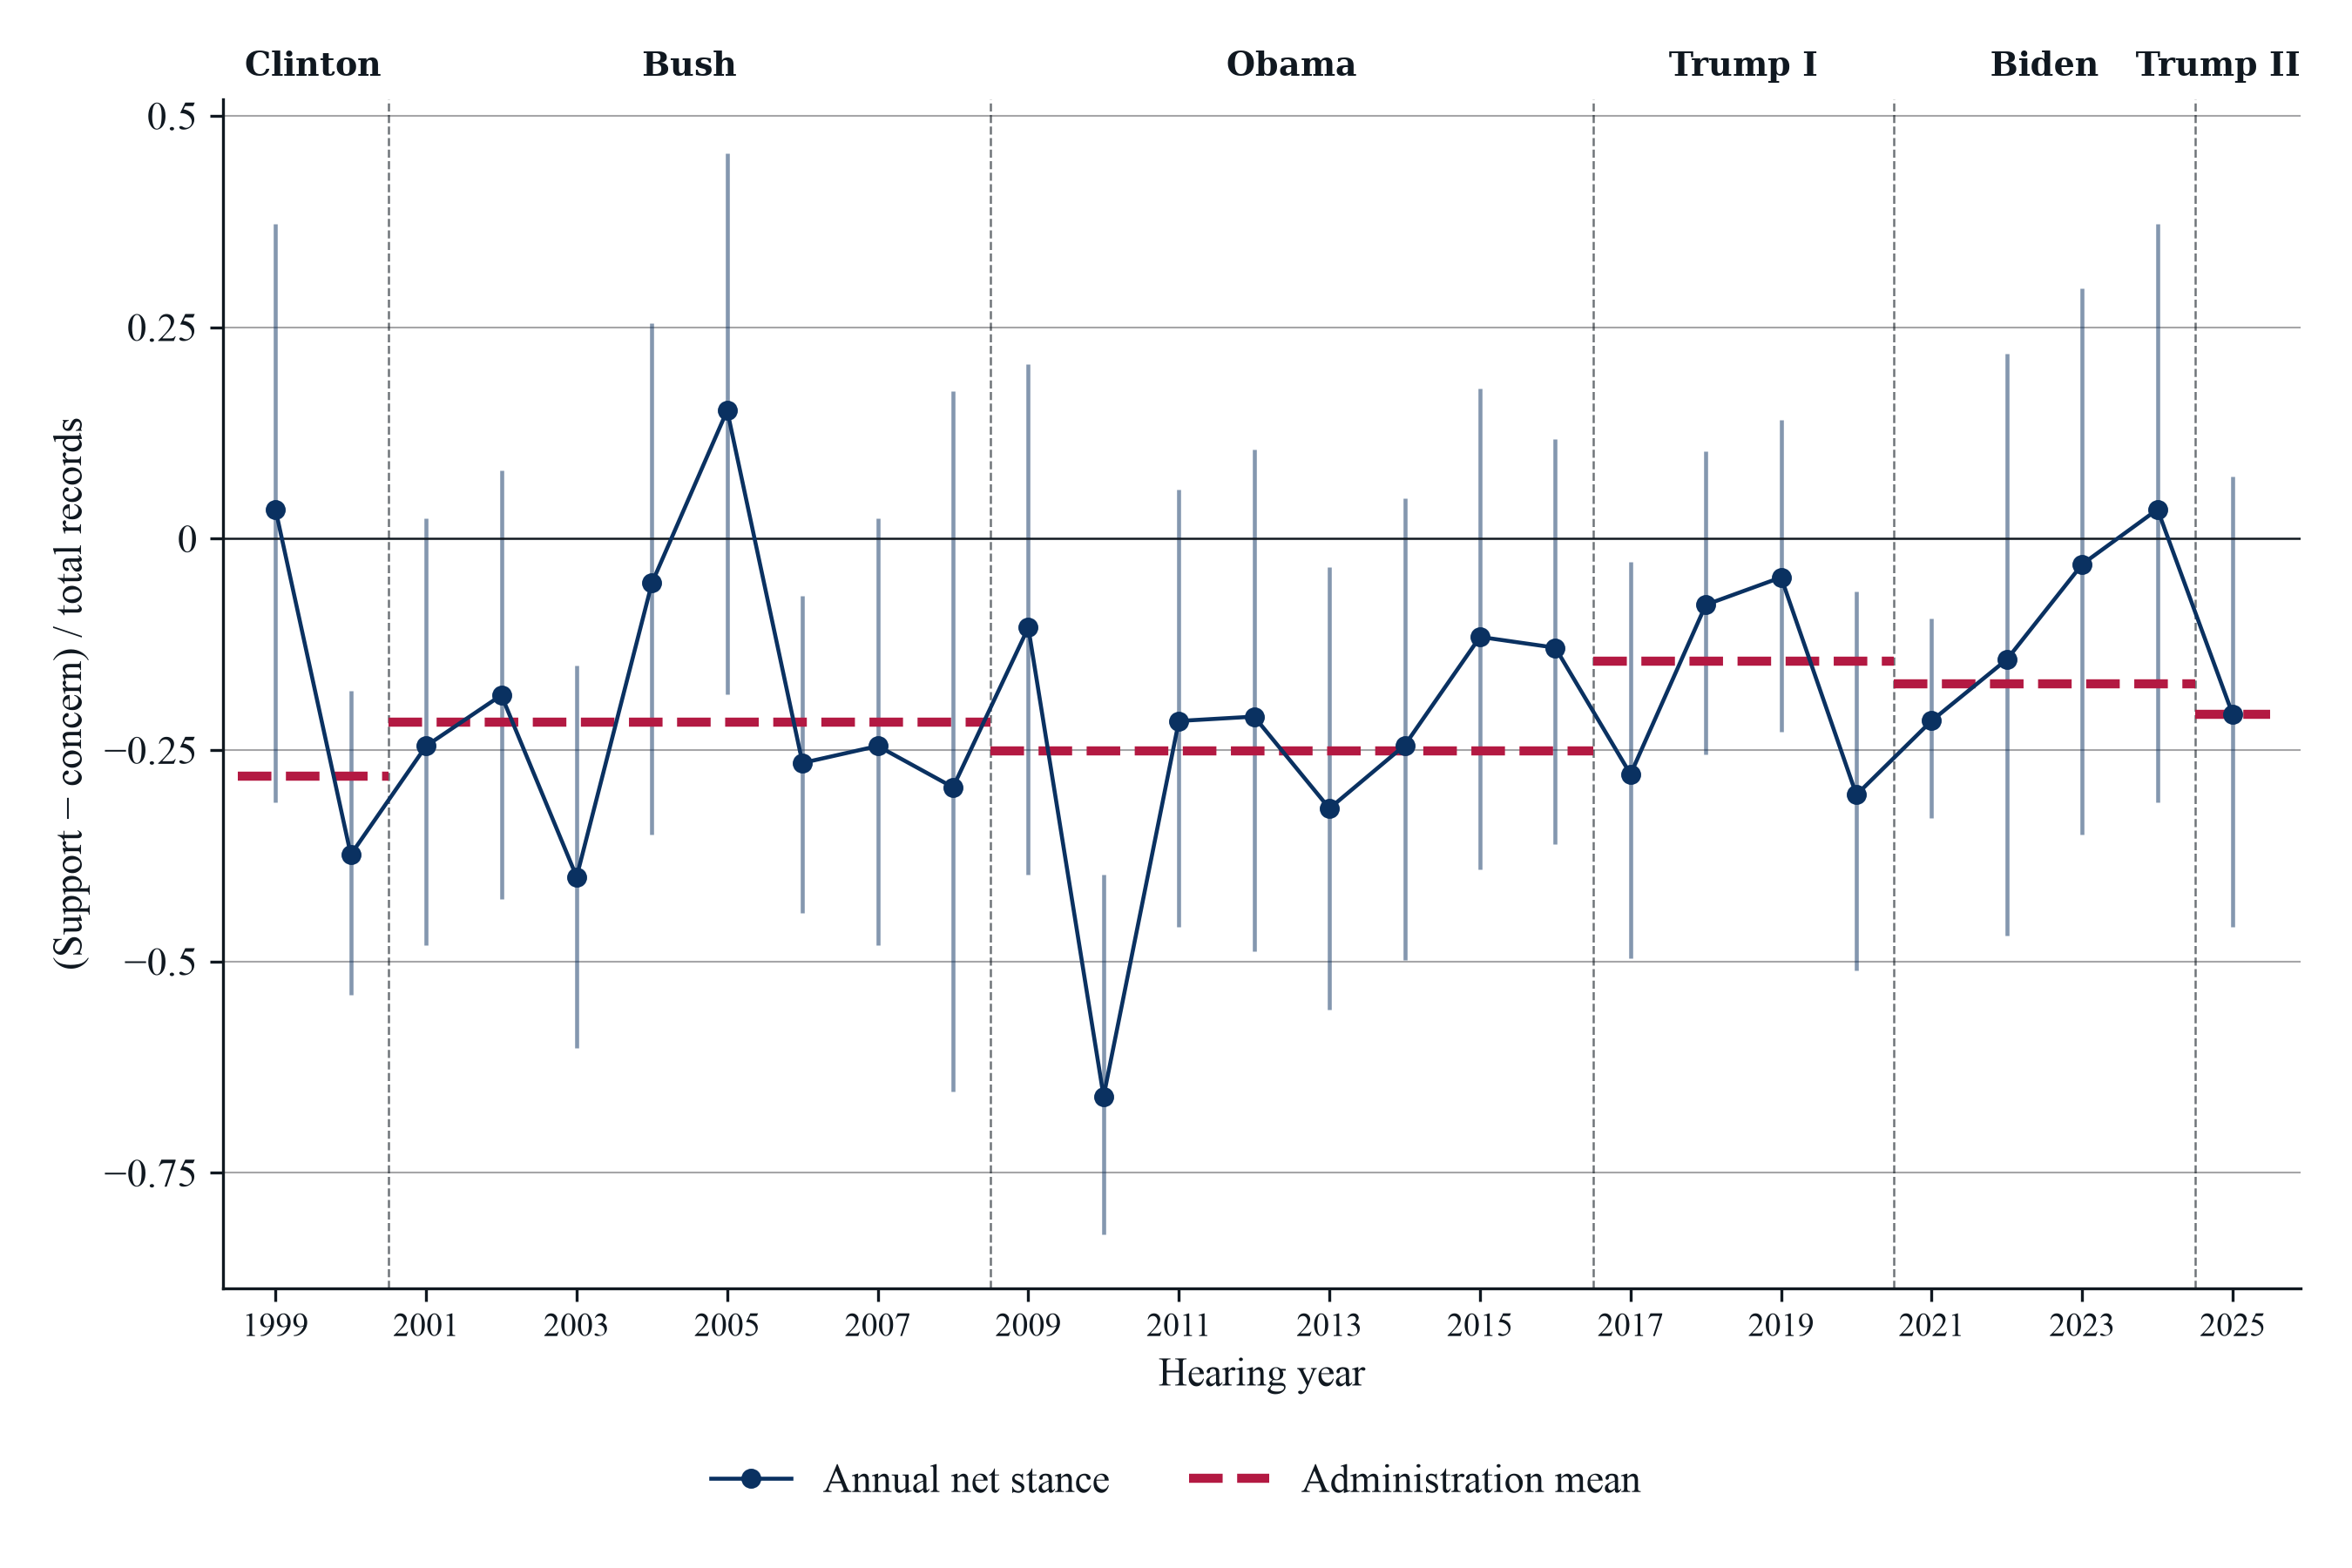

*Notes*: Sample: House Science and Senate Commerce, 1999–2025: 5 manually grouped privacy topics, 551 hearings, 1,086 legislator speech turns, and 1,654 stance records. Each record is a legislator's extracted position on a topic. Index = (support − concern) / total records; 0 indicates equal counts. Blue bars show 95 percent Wilson intervals, assuming independent records (no hearing-level clustering). Red dashed lines show pooled administration means; vertical dashed lines mark calendar-year boundaries between administrations.

*Source*: Saved legislator stance extraction and the approved manual topic grouping.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.2/fig_privacy_group_net_stance


In [14]:
figure_name = "fig_privacy_group_net_stance"
figure_title = "Figure 1. Net Stance in Privacy and Digital Consumer Protection"
figure, axis = plt.subplots()
figure.subplots_adjust(
    left=0.12, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=0.9, bottom=0.2
)
years = annual_counts.index.to_numpy()

axis.vlines(
    years, annual_counts["net_ci_lower"], annual_counts["net_ci_upper"],
    color=BLUE, alpha=0.5, linewidth=1.1, zorder=2,
)
axis.plot(
    years, annual_counts["net_stance"], color=BLUE, marker="o",
    markersize=4.5, linewidth=1.1, label="Annual net stance", zorder=4,
)
for position, period in enumerate(administration_counts.itertuples(index=False)):
    axis.hlines(
        period.net_stance, period.first_year - 0.5, period.last_year + 0.5,
        color=RED, linewidth=2.5, linestyle="--", zorder=3,
        label="Administration mean" if position == 0 else "_nolegend_",
    )
interval_minimum = min(0, annual_counts["net_ci_lower"].min())
interval_maximum = max(0, annual_counts["net_ci_upper"].max())
interval_padding = (interval_maximum - interval_minimum) * Y_PADDING_SHARE
axis_limits = (interval_minimum - interval_padding, interval_maximum + interval_padding)
axis.set_ylim(*axis_limits)
tick_positions = MaxNLocator(nbins=7).tick_values(*axis_limits)
tick_positions = tick_positions[(tick_positions >= axis_limits[0]) & (tick_positions <= axis_limits[1])]
tick_labels = ["0" if value == 0 else f"{value:g}".replace("-", "−") for value in tick_positions]
axis.set_yticks(tick_positions, labels=tick_labels)
axis.set_ylabel("(Support − concern) / total records")
axis.set_xlabel("Hearing year")
axis.set_xlim(YEAR_MIN - 0.7, YEAR_MAX + 0.9)
axis.set_xticks(range(YEAR_MIN, YEAR_MAX + 1, 2))
axis.tick_params(axis="x", labelsize=9)
axis.spines[["top", "right"]].set_visible(False)
for tick, gridline in zip(axis.get_yticks(), axis.get_ygridlines()):
    if tick == 0:
        gridline.set_visible(False)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)

administration_labels = []
for administration, first_year, last_year in ADMINISTRATION_WINDOWS:
    if first_year > YEAR_MIN:
        axis.axvline(first_year - 0.5, color=BLACK, linestyle="--", linewidth=0.6, alpha=0.6)
    label_position = axis.get_xlim()[1] if last_year == YEAR_MAX else (first_year + last_year) / 2
    label_alignment = "right" if last_year == YEAR_MAX else "center"
    administration_labels.append(axis.text(
        label_position, 1.02, administration,
        transform=axis.get_xaxis_transform(), ha=label_alignment, va="baseline",
        fontsize=9, clip_on=False, **BOLD_TEXT,
    ))

legend = figure.legend(
    loc="lower center", bbox_to_anchor=(0.5, MARGIN_INCHES / FIGURE_HEIGHT),
    bbox_transform=figure.transFigure, ncol=2, frameon=False, borderaxespad=0,
)
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
label_top = max(label.get_window_extent(renderer).y1 for label in administration_labels)
top_shift = (figure.bbox.height - margin_pixels - label_top) / figure.bbox.height
legend_top = legend.get_window_extent(renderer).y1
label_bottom = axis.xaxis.label.get_window_extent(renderer).y0
bottom_shift = (legend_top + margin_pixels - label_bottom) / figure.bbox.height
figure.subplots_adjust(
    left=figure.subplotpars.left + left_shift,
    top=figure.subplotpars.top + top_shift,
    bottom=figure.subplotpars.bottom + bottom_shift,
)

for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (
    f"Sample: {sample_description} Each record is a legislator's extracted position on a topic. "
    "Index = (support − concern) / total records; 0 indicates equal counts. "
    "Blue bars show 95 percent Wilson intervals, assuming independent records (no hearing-level clustering). "
    "Red dashed lines show pooled administration means; vertical dashed lines mark calendar-year "
    "boundaries between administrations."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {figure_source}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")